# 05 · Does *Alice in Wonderland* push the results?

The model has memorised *Alice* (`creative_gut_alice`): its #1 guess is the real word 74% of the time
(other creative texts: 28–49%), and half its words get over 90% probability. A memorised creative text looks
"factual" to the model (confident, predictable). So this notebook redoes the clustering **without it**
(24 texts: 12 factual, 12 creative) and compares with all 25.

Series (one at a time, whole curves, nothing averaged):

| per measured word (noun/verb) | per token |
|---|---|
| LCA height, GloVe distance, Qwen-embedding distance, each with top 1 / top 3 / top 5 / likely-only guesses (notebook 04) | surprisal, entropy, Rényi |
| surprisal, entropy, Rényi at the word | |

Clustering is the same as notebooks 02 and 04: raw / shape-only × DTW / Euclidean × DBSCAN, KMeans,
DTW-KMeans, k-medoids, k = 2.

Two comparisons per series:
- **best run**: the best of the 16 runs, picked separately with and without *Alice*;
- **same run**: the run that was best with *Alice*, repeated without it (so the method is fixed and only the data changes).

Scores are given as a **share** of texts sorted correctly, since the totals differ (25 vs 24).

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
warnings.filterwarnings("ignore")

# walk up from the notebook's folder until we find the repo root (the folder holding lca_core.py)
ROOT = Path.cwd()
while not (ROOT / "lca_core.py").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("lca_core.py not found in this folder or any parent folder")
    ROOT = ROOT.parent
HERE = ROOT / "src" / "note_books" / "Qwen7B"
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import mannwhitneyu

from lca_core import kind, load_token_embeddings
from timeseries_tools import METRIC_PREFIXES, VARIANTS, add_guess_variants, cluster_curves, curve

RESULTS = HERE / "results"
FIG_DIR = RESULTS / "figures_without_alice"
FIG_DIR.mkdir(parents=True, exist_ok=True)
ALICE = "creative_gut_alice"

WITH_COLOR = "#6250d6"       # with Alice (25 texts)
WITHOUT_COLOR = "#1baf7a"    # without Alice (24 texts)
INK = "#0b0b0b"
INK_SOFT = "#52514e"
GRID = "#e4e3df"


def clean_axes(ax, grid_axis="x"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_SOFT, labelsize=9)
    ax.grid(axis=grid_axis, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def save(fig, name, tries=3):
    # OneDrive sometimes refuses the first overwrite of a synced file (OSError 22): remove it and retry
    path = FIG_DIR / name
    for attempt in range(tries):
        try:
            fig.savefig(path, dpi=110, bbox_inches="tight")
            return
        except OSError:
            if attempt == tries - 1:
                print(f"could not save {name} (file locked?)")
                return
            path.unlink(missing_ok=True)


all_names = sorted(path.stem for path in (RESULTS / "words").glob("*.csv"))
tok, E = load_token_embeddings("Qwen/Qwen2.5-7B-Instruct")
words = {}
tokens = {}
for name in all_names:
    words[name] = add_guess_variants(pd.read_csv(RESULTS / "words" / f"{name}.csv"), tok, E)
    tokens[name] = pd.read_csv(RESULTS / "tokens" / f"{name}.csv")

# (table, column, measurement, version, time axis)
SERIES = []
for prefix, metric in METRIC_PREFIXES.items():
    for variant, variant_title in VARIANTS.items():
        SERIES.append((words, f"{prefix}_{variant}", metric, variant_title, "per word"))
for column, title in [("surprisal", "surprisal"), ("entropy", "entropy"), ("renyi", "Rényi")]:
    SERIES.append((words, column, title, "", "per word"))
for column, title in [("surprisal", "surprisal"), ("entropy", "entropy"), ("renyi", "Rényi")]:
    SERIES.append((tokens, column, title, "", "per token"))
print(len(all_names), "texts,", len(SERIES), "series")

25 texts, 18 series


## 1. Run every clustering with and without *Alice*
Takes a few minutes (the per-token DTW runs are the slow part).

In [2]:
TEXT_SETS = {"with Alice (25)": all_names,
             "without Alice (24)": [n for n in all_names if n != ALICE]}

rows = []
for table, column, measurement, version, axis in SERIES:
    for set_name, names in TEXT_SETS.items():
        curves = [curve(table[n], column) for n in names]
        true_kinds = np.array([kind(n) for n in names])
        for run in cluster_curves(curves, true_kinds):
            labels = run.pop("labels")
            run.update({"axis": axis, "measurement": measurement, "version": version, "texts": set_name,
                        "total": len(names), "share correct": run["sorted correctly"] / len(names)})
            if ALICE in names:
                alice_index = names.index(ALICE)
                alice_cluster = labels[alice_index]
                if alice_cluster == -1:
                    run["Alice landed with"] = "noise"
                else:
                    members = true_kinds[labels == alice_cluster]
                    run["Alice landed with"] = pd.Series(members).mode()[0]
            rows.append(run)
runs = pd.DataFrame(rows)
runs["series"] = (runs["measurement"] + " " + runs["version"]).str.strip() + " (" + runs["axis"] + ")"
runs.to_csv(RESULTS / "clustering_runs_without_alice.csv", index=False)
print(len(runs), "runs")

432 runs


## 2. Best run per series: with vs without *Alice*

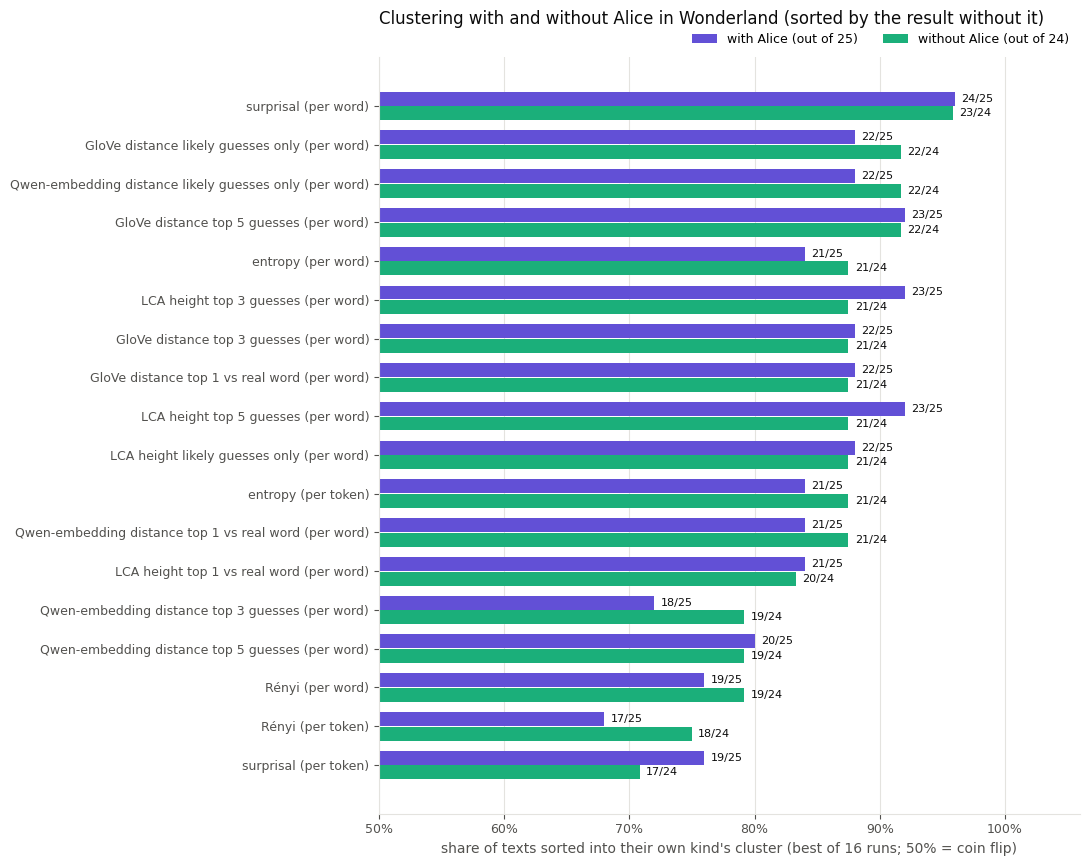

series,with Alice: best,with: share,with: ARI,Alice landed with,without: best,without: share,without: ARI,without: factual,without: creative,without: same run as with,same run: ARI,best run with Alice,best run without Alice
surprisal (per word),24/25,96%,0.84,creative,23/24,96%,0.83,12/12,11/12,23/24,0.83,"shape only, DTW, k-medoids","shape only, DTW, k-medoids"
GloVe distance likely guesses only (per word),22/25,88%,0.56,creative,22/24,92%,0.68,10/12,12/12,21/24,0.54,"raw, DTW, k-medoids","raw, DTW, DTW-KMeans"
Qwen-embedding distance likely guesses only (per word),22/25,88%,0.56,creative,22/24,92%,0.68,10/12,12/12,4/24,0.03,"raw, DTW, DBSCAN","shape only, DTW, k-medoids"
GloVe distance top 5 guesses (per word),23/25,92%,0.69,creative,22/24,92%,0.68,10/12,12/12,22/24,0.68,"raw, DTW, k-medoids","raw, DTW, k-medoids"
entropy (per word),21/25,84%,0.44,factual,21/24,88%,0.54,10/12,11/12,21/24,0.54,"raw, DTW, DTW-KMeans","raw, DTW, DTW-KMeans"
LCA height top 3 guesses (per word),23/25,92%,0.69,creative,21/24,88%,0.54,10/12,11/12,14/24,0.01,"raw, DTW, DTW-KMeans","shape only, DTW, k-medoids"
GloVe distance top 3 guesses (per word),22/25,88%,0.56,creative,21/24,88%,0.54,12/12,9/12,21/24,0.54,"raw, DTW, k-medoids","raw, DTW, k-medoids"
GloVe distance top 1 vs real word (per word),22/25,88%,0.56,creative,21/24,88%,0.54,11/12,10/12,21/24,0.54,"raw, DTW, DTW-KMeans","raw, DTW, DTW-KMeans"
LCA height top 5 guesses (per word),23/25,92%,0.69,creative,21/24,88%,0.54,9/12,12/12,16/24,0.09,"raw, DTW, DTW-KMeans","shape only, DTW, k-medoids"
LCA height likely guesses only (per word),22/25,88%,0.56,creative,21/24,88%,0.54,9/12,12/12,21/24,0.54,"shape only, DTW, k-medoids","shape only, DTW, k-medoids"


In [3]:
RUN_KEYS = ["scaling", "distance", "method"]
summary_rows = []
for series_name, series_runs in runs.groupby("series", sort=False):
    with_runs = series_runs[series_runs["texts"] == "with Alice (25)"]
    without_runs = series_runs[series_runs["texts"] == "without Alice (24)"]
    best_with = with_runs.sort_values(["sorted correctly", "ARI"], ascending=False).iloc[0]
    best_without = without_runs.sort_values(["sorted correctly", "ARI"], ascending=False).iloc[0]
    same_run = without_runs
    for key in RUN_KEYS:
        same_run = same_run[same_run[key] == best_with[key]]
    same_run = same_run.iloc[0]
    summary_rows.append({
        "series": series_name,
        "with Alice: best": f"{best_with['sorted correctly']}/25",
        "with: share": best_with["share correct"],
        "with: ARI": best_with["ARI"],
        "Alice landed with": best_with["Alice landed with"],
        "without: best": f"{best_without['sorted correctly']}/24",
        "without: share": best_without["share correct"],
        "without: ARI": best_without["ARI"],
        "without: factual": f"{best_without['factual correct']}/12",
        "without: creative": f"{best_without['creative correct']}/12",
        "without: same run as with": f"{same_run['sorted correctly']}/24",
        "same run: ARI": same_run["ARI"],
        "best run with Alice": f"{best_with['scaling'].replace('standardised', 'shape only')}, "
                               f"{best_with['distance']}, {best_with['method']}",
        "best run without Alice": f"{best_without['scaling'].replace('standardised', 'shape only')}, "
                                  f"{best_without['distance']}, {best_without['method']}"})
summary = pd.DataFrame(summary_rows).sort_values("without: share", ascending=False)

fig, ax = plt.subplots(figsize=(11, 0.42 * len(summary) + 1.2))
y = np.arange(len(summary))[::-1]
ax.barh(y + 0.19, summary["with: share"], height=0.36, color=WITH_COLOR, label="with Alice (out of 25)")
ax.barh(y - 0.19, summary["without: share"], height=0.36, color=WITHOUT_COLOR, label="without Alice (out of 24)")
for position, (_, row) in zip(y, summary.iterrows()):
    ax.text(row["with: share"] + 0.005, position + 0.19, row["with Alice: best"], va="center", fontsize=8, color=INK)
    ax.text(row["without: share"] + 0.005, position - 0.19, row["without: best"], va="center", fontsize=8,
            color=INK)
ax.set_yticks(y, summary["series"], fontsize=9)
ax.set_xlim(0.5, 1.06)
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("share of texts sorted into their own kind's cluster (best of 16 runs; 50% = coin flip)",
              color=INK_SOFT)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2, fontsize=9)
ax.set_title("Clustering with and without Alice in Wonderland (sorted by the result without it)",
             loc="left", fontsize=12, color=INK, pad=24)
clean_axes(ax)
fig.tight_layout()
save(fig, "1_best_run_with_vs_without_alice.png")
plt.show()

summary.style.format({"with: share": "{:.0%}", "without: share": "{:.0%}", "with: ARI": "{:.2f}",
                      "without: ARI": "{:.2f}", "same run: ARI": "{:.2f}"}).hide(axis="index")

## 3. One number per text, with and without *Alice*
Median and ups and downs (SD) of each curve; **pairs in order** = share of (factual, creative) pairs on the
expected side (100% = perfect split, 50% = coin flip).

In [4]:
def separation(values_factual, values_creative):
    factual_higher = (values_factual[:, None] > values_creative[None, :]).mean()
    factual_lower = (values_factual[:, None] < values_creative[None, :]).mean()
    p_value = mannwhitneyu(values_factual, values_creative).pvalue
    if factual_higher >= factual_lower:
        return factual_higher, p_value, "factual higher"
    return factual_lower, p_value, "creative higher"


one_number_rows = []
for table, column, measurement, version, axis in SERIES:
    series_name = f"{measurement} {version}".strip() + f" ({axis})"
    for statistic in ["median", "SD"]:
        row = {"series": series_name, "number": statistic}
        for set_name, names in TEXT_SETS.items():
            values = {"factual": [], "creative": []}
            for name in names:
                values_of_text = curve(table[name], column)
                if statistic == "median":
                    values[kind(name)].append(np.median(values_of_text))
                else:
                    values[kind(name)].append(values_of_text.std())
            in_order, p_value, direction = separation(np.array(values["factual"]), np.array(values["creative"]))
            short = "with" if "with Alice" in set_name else "without"
            row[f"{short}: pairs in order"] = in_order
            row[f"{short}: p"] = p_value
            row[f"{short}: direction"] = direction
        one_number_rows.append(row)
one_number = pd.DataFrame(one_number_rows)
one_number["change"] = one_number["without: pairs in order"] - one_number["with: pairs in order"]
one_number = one_number.sort_values("without: pairs in order", ascending=False)
one_number.head(20).style.format({"with: pairs in order": "{:.0%}", "without: pairs in order": "{:.0%}",
                                  "with: p": "{:.5f}", "without: p": "{:.5f}", "change": "{:+.0%}"}
                                 ).hide(axis="index")

series,number,with: pairs in order,with: p,with: direction,without: pairs in order,without: p,without: direction,change
Qwen-embedding distance top 5 guesses (per word),SD,100%,0.00002,creative higher,100%,0.00004,creative higher,+0%
GloVe distance top 5 guesses (per word),SD,100%,0.00002,creative higher,100%,0.00004,creative higher,+0%
Qwen-embedding distance top 3 guesses (per word),SD,97%,0.00008,creative higher,97%,0.00012,creative higher,-0%
GloVe distance top 3 guesses (per word),SD,96%,0.00010,creative higher,96%,0.00016,creative higher,-0%
GloVe distance top 3 guesses (per word),median,95%,0.00016,factual higher,94%,0.00025,factual higher,-0%
GloVe distance top 5 guesses (per word),median,93%,0.00030,factual higher,94%,0.00031,factual higher,+1%
Rényi (per token),median,83%,0.00509,factual higher,90%,0.00111,factual higher,+6%
entropy (per word),median,82%,0.00709,creative higher,89%,0.00135,creative higher,+7%
surprisal (per word),median,81%,0.00978,creative higher,88%,0.00201,creative higher,+7%
GloVe distance likely guesses only (per word),SD,87%,0.00176,factual higher,88%,0.00201,factual higher,+0%


## 4. Findings

**Clustering hardly changes.** The best series stay the best, with about the same share sorted correctly:

| series | with *Alice* | without *Alice* |
|---|---|---|
| surprisal per word (shape only, DTW, k-medoids) | 24/25 (96%) | 23/24 (96%) |
| GloVe top 5 (raw, DTW, k-medoids) | 23/25 (92%) | 22/24 (92%) |
| GloVe / Qwen-embedding likely-only | 22/25 (88%) | 22/24 (92%) |
| LCA height top 3 / top 5 | 23/25 (92%) | 21/24 (88%) |

In the best runs of the meaning measurements (LCA, GloVe, Qwen embeddings), *Alice* was already sorted with the
creative texts, so removing it changes little. In the best runs of entropy, Rényi and per-token surprisal, *Alice*
landed with the **factual** texts. Memorisation makes it look factual to the model's confidence.

**The confidence measurements get clearer without *Alice*** (one number per text, pairs in order):

| | with | without |
|---|---|---|
| surprisal per word, median | 81% | 88% |
| entropy per word, median | 82% | 89% |
| Rényi per token, median | 83% | 90% |
| surprisal per token, median | 78% | 84% |

The meaning-spread numbers (GloVe/Qwen-embedding SD, 100%; GloVe median, 93–95%) don't move. They don't depend on
whether the model knows the text by heart.

**LCA's best clustering is fragile.** The run that gave 23/25 with *Alice* (raw, DTW-KMeans) gives only 14–16/24
without it, while the best run on 24 texts reaches 21/24. GloVe and surprisal keep the same run and the same
result, so they are the more reliable choices.

**Bottom line:** *Alice* doesn't drive the clustering results. It weakens the confidence-based numbers (surprisal,
entropy, Rényi), because a memorised creative text looks factual to them. For those measurements, memorised famous
texts should be avoided or flagged.